# The Absolute Most Basic Diffraction Analysis of a Sample Suitable for Total Beginners: The Aluminum Files.

-----------

Here's the basic idea: 

1.   Load an image image of aluminum.
2.   Plot it, just to make sure it's reasonable.
3.   Calibrate it so we can know our scale and do something reasonable in nanometers.
4.   Measure things about spots in the diffraction patterns in reciprocal space.
5.   Do "math stuff" to solve for material structure and spacing in the normal world.
6.   Profit!


Before we begin, we need to do some basic housekeeping. Tell the matplotlib package that we want our plots drawn into our jupyter notebook, import Hyperspy so we can use it, tweak a setting to silence some harmless complaints, and finally tell matplotlib to not complain just because we've opened a lot of plots. We have plenty of memory.

In [35]:
%matplotlib widget

import hyperspy.api as hs

hs.preferences.GUIs.enable_traitsui_gui = False  # needed to suppress harmless traitsui-vs-widget warning

import matplotlib as plt

plt.rcParams.update({'figure.max_open_warning': 0})

# DO NOT RUN THE FOLLOWING CELL

It is strictly for testing jupyter itself. It will be removed soon.

In [3]:
from __future__ import print_function, division, absolute_import
from pylab import *
import time

import matplotlib.backends
import matplotlib.pyplot as p
import os.path


def is_backend_module(fname):
    """Identifies if a filename is a matplotlib backend module"""
    return fname.startswith('backend_') and fname.endswith('.py')

def backend_fname_formatter(fname): 
    """Removes the extension of the given filename, then takes away the leading 'backend_'."""
    return os.path.splitext(fname)[0][8:]

# get the directory where the backends live
backends_dir = os.path.dirname(matplotlib.backends.__file__)

# filter all files in that directory to identify all files which provide a backend
backend_fnames = filter(is_backend_module, os.listdir(backends_dir))

backends = [backend_fname_formatter(fname) for fname in backend_fnames]

print("supported backends: \t" + str(backends))

# validate backends
backends_valid = []
for b in backends:
    try:
        p.switch_backend(b)
        backends_valid += [b]
    except:
        continue

print("valid backends: \t" + str(backends_valid))


# try backends performance
for b in backends_valid:

    ion()
    try:
        p.switch_backend(b)


        clf()
        tstart = time.time()               # for profiling
        x = arange(0,2*pi,0.01)            # x-array
        line, = plot(x,sin(x))
        for i in arange(1,200):
            line.set_ydata(sin(x+i/10.0))  # update the data
            draw()                         # redraw the canvas

        print(b + ' FPS: \t' , 200/(time.time()-tstart))
        ioff()

    except:
        print(b + " error :(")

supported backends: 	['template', 'qtcairo', 'qt', 'gtk3cairo', 'tkagg', 'gtk4agg', 'qt5agg', 'qt5', 'gtk3agg', 'cairo', 'pdf', 'wxagg', 'pgf', 'mixed', 'macosx', 'gtk4', 'tkcairo', 'gtk3', 'wxcairo', 'nbagg', 'webagg_core', 'gtk4cairo', 'wx', 'qt5cairo', 'svg', 'webagg', 'ps', 'qtagg', 'agg']
valid backends: 	['template', 'pdf', 'pgf', 'macosx', 'nbagg', 'svg', 'webagg', 'ps', 'agg']
template FPS: 	 211.14108855629277
pdf FPS: 	 204.80030000043945
pgf FPS: 	 217.34594442637965
macosx FPS: 	 222.1990067989875
nbagg FPS: 	 225.08562185995044
svg FPS: 	 225.15219754411862
webagg FPS: 	 224.54926100594417
ps FPS: 	 220.99599585754748
agg FPS: 	 219.3829112889538


In [14]:
s = hs.load("../aluminumData/Al-DP-problem.tif")
print(s)



<Signal2D, title: , dimensions: (|501, 334)>


### Take a peek

It's a good idea to just take a look at the images you're working with, mostly just to make sure they were read correctly and are images of what you thought they were.

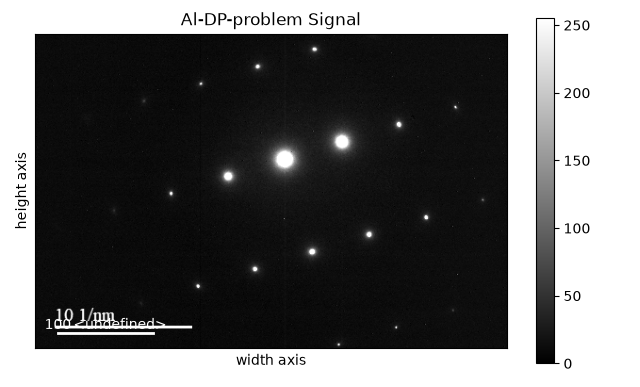

In [15]:
s.plot()

### Calibration

Question: does that image come straight off the 'scope in units of 1/nm? Does it fundamentally, physically capture diffraction patterns, or _something_ process an image into this?


In [16]:
print(s.calibrate())

None


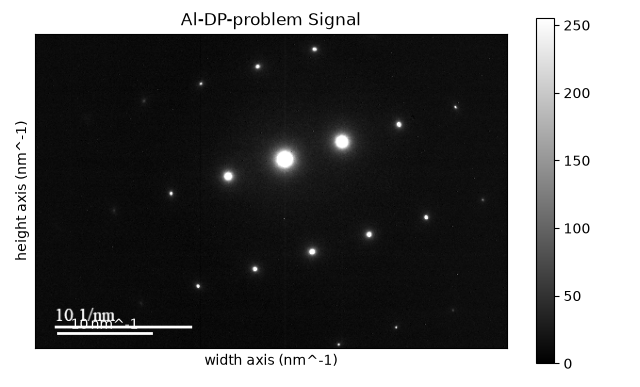

In [18]:
s.plot()

# The following illustrates fft() and ifft() using built-in data

ifft() is the inverse fft function. The "signal" is one that comes built in to hyperspy for learning and for quick doodles.

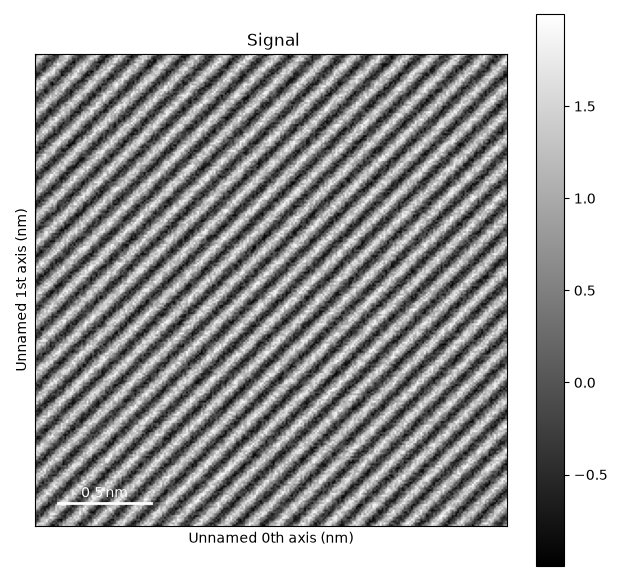

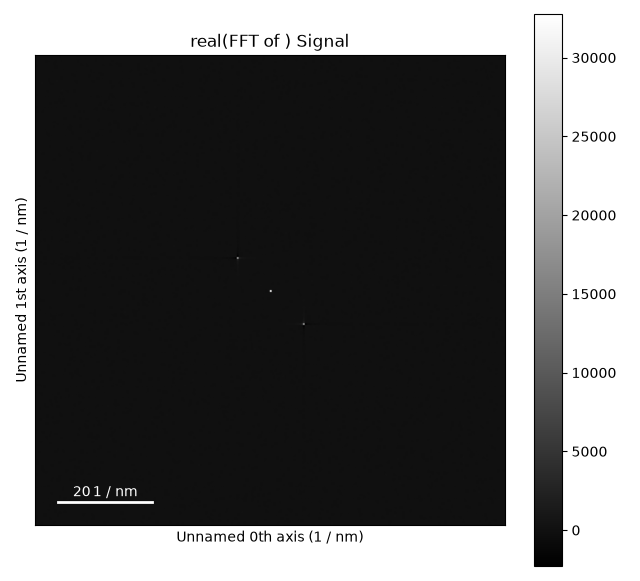

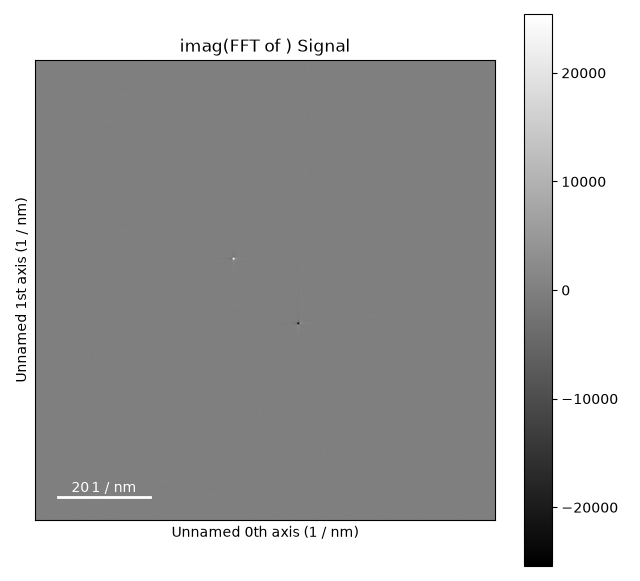

In [17]:
#im = hs.data.wave_image()
#fft_shifted = im.fft(shift=True)
#fft_shifted.plot()

im = hs.data.wave_image()
im.plot()
fft_shifted = im.fft(shift=True)
fft_shifted.plot()

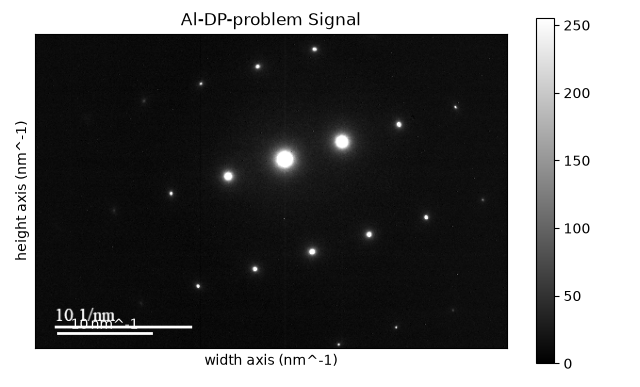

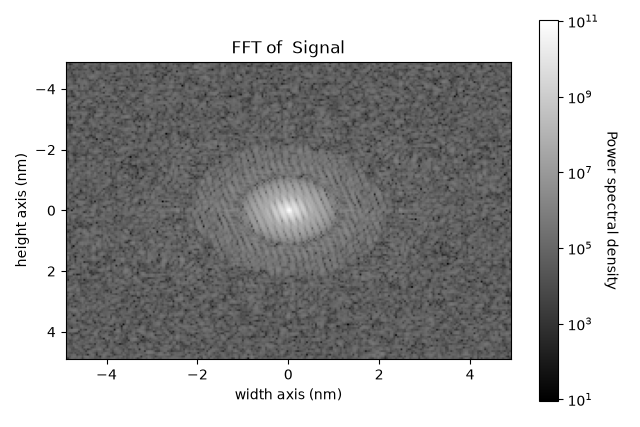

In [21]:
new_s = s
rectangular_roi = hs.roi.RectangularROI()
new_s.plot()
roi2D = rectangular_roi.interactive(new_s, color="red")

s_fft = hs.interactive(roi2D.fft, apodization=True, shift=True, recompute_out_event=None)
s_fft.plot(power_spectrum=True)


### And once we have a power spectrum fft we like, we can run it through ifft() to go back to the real world:

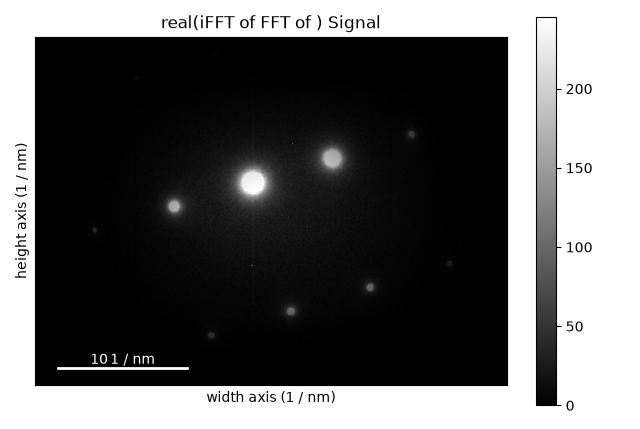

In [24]:
#sff = sf_result.ifft()
sff = s_fft.ifft()
sff.plot()

# Let's load some diffraction patterns and see what fft() and ifft() do.

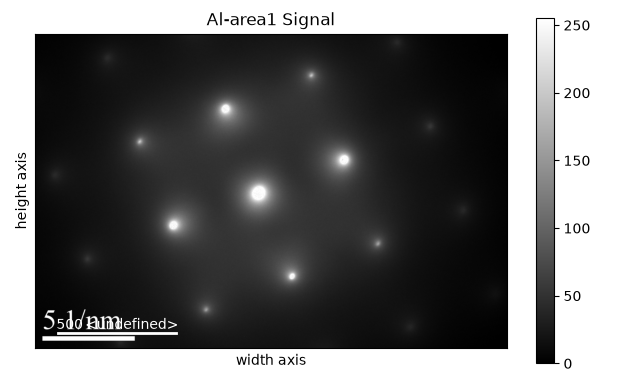

In [36]:
ala1 = hs.load("../aluminumData/Al-area1.tif")
ala2 = hs.load("../aluminumData/Al-area2.tif")

ala1.plot()

### There's a good chance you'll need to hit "l" ("ell") to get enough dynamic range to see anything.

In [38]:
ala1.calibrate()

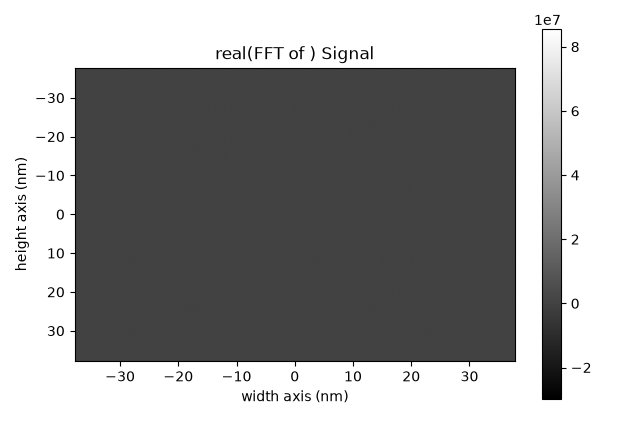

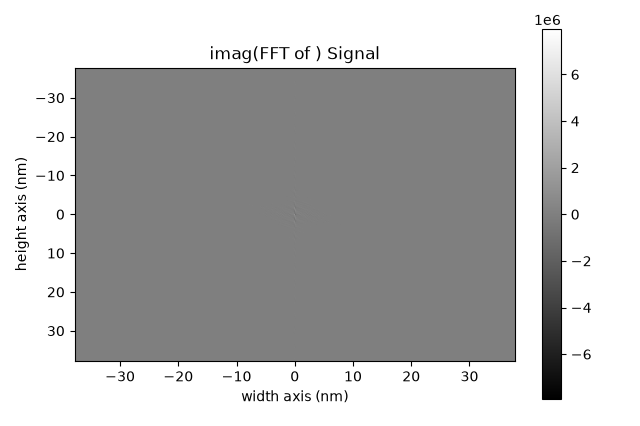

In [39]:
ala1_shifted = ala1.fft(shift=True)
ala1_shifted.plot()


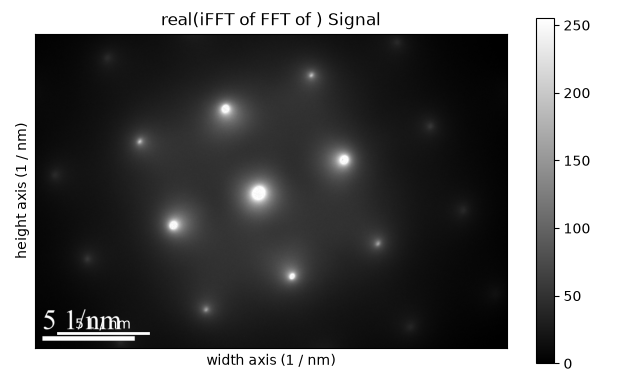

In [40]:
rehydrated = ala1_shifted.ifft()
rehydrated.plot()

### Repeat, this time for area2 - same material, different rotation.

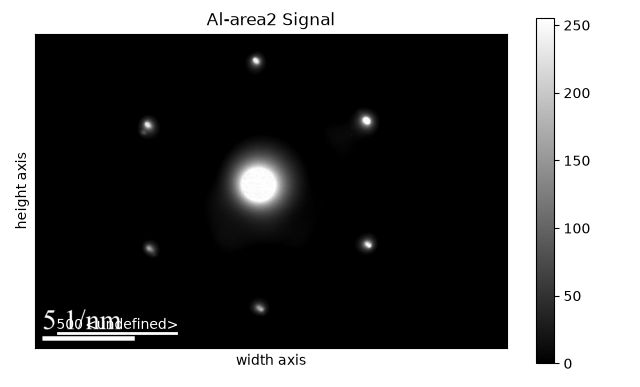

WARNING | Hyperspy | Units are not set or cannot be recognized (hyperspy.signal:5015)
WARNING | Hyperspy | Units are not set or cannot be recognized (hyperspy.signal:5015)


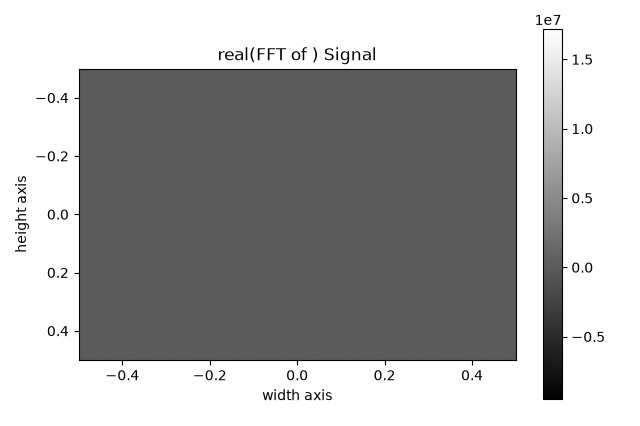

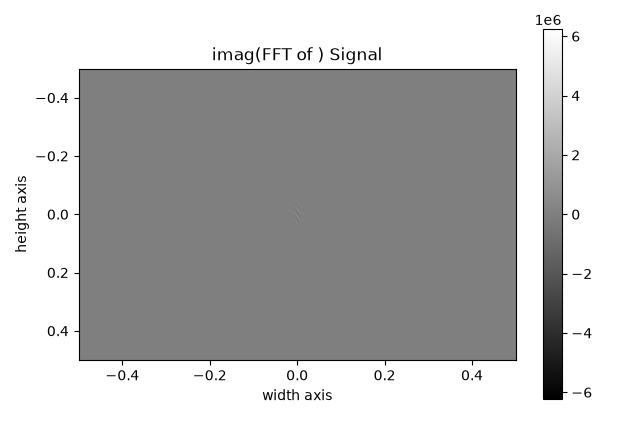

WARNING | Hyperspy | Units are not set or cannot be recognized (hyperspy.signal:5102)
WARNING | Hyperspy | Units are not set or cannot be recognized (hyperspy.signal:5102)


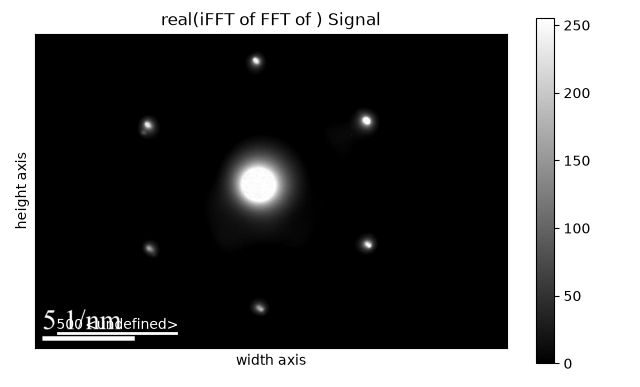

In [34]:
ala2.plot()
ala2_shifted = ala2.fft(shift=True)
ala2_shifted.plot()
backAgain = ala2_shifted.ifft()
backAgain.plot()